In [1]:
# Import necessary libraries
import warnings
warnings.filterwarnings("ignore")
import torch
import pandas as pd
import numpy as np
import scanpy as sc
import os
import yaml
from pathlib import Path
from tqdm import tqdm
from sklearn.metrics import adjusted_rand_score as ari_score
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt
import harmonypy as hm

# Set environment variables
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

# Import SEDR modules
from SEDR.graph_func import graph_construction, combine_graph_dict
from SEDR.utils_func import adata_preprocess, fix_seed
from SEDR.SEDR_model import Sedr
from SEDR.clustering_func import mclust_R

# Set random seed for reproducibility
fix_seed(42)

# Define helper function for slice_id mapping
def mapping2int(string_array):
    mapping = {}
    result = []
    for string in string_array:
        if string not in mapping:
            mapping[string] = len(mapping)
        result.append(mapping[string])
    return result, mapping

# Data loading function
def get_data(proj_list, k):
    global graph_dict
    data_root = Path(r'C:\Code\Data\DLPFC')
    result, mapping = mapping2int(proj_list)
    for proj_name in tqdm(proj_list):
        adata_tmp = sc.read_visium(data_root / proj_name )
        adata_tmp.var_names_make_unique()

        adata_tmp.obs['batch_name'] = proj_name
        adata_tmp.obs['slice_id'] = mapping[proj_name]

        ##### Load layer_guess label, if have
        truth_path = data_root / proj_name / f'{proj_name}_truth.txt'
        Ann_df = pd.read_csv(truth_path, sep='\t', header=None, index_col=0)
        Ann_df.columns = ['Ground Truth']
        adata_tmp.obs['layer_guess'] = Ann_df.loc[adata_tmp.obs_names, 'Ground Truth']
        adata_tmp = adata_tmp[~pd.isnull(adata_tmp.obs['layer_guess'])]

        graph_dict_tmp = graph_construction(adata_tmp, k)
        if proj_name == proj_list[0]:
            adata = adata_tmp
            graph_dict = graph_dict_tmp
            name = proj_name
            adata.obs['proj_name'] = proj_name
        else:
            var_names = adata.var_names.intersection(adata_tmp.var_names)
            adata = adata[:, var_names]
            adata_tmp = adata_tmp[:, var_names]
            adata_tmp.obs['proj_name'] = proj_name

            adata = adata.concatenate(adata_tmp)
            graph_dict = combine_graph_dict(graph_dict, graph_dict_tmp)
            name = name + '_' + proj_name

    adata.layers['count'] = adata.X.toarray()
    sc.pp.filter_genes(adata, min_cells=50)
    sc.pp.filter_genes(adata, min_counts=10)
    sc.pp.normalize_total(adata, target_sum=1e6)
    sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)
    adata = adata[:, adata.var['highly_variable'] == True]
    sc.pp.scale(adata)

    adata_X = PCA(n_components=200, random_state=42).fit_transform(adata.X)
    adata.obsm['X_pca'] = adata_X
    return adata, graph_dict

In [2]:
# Main execution
# Define parameters
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
proj_list = ['151673', '151674', '151675', '151676']

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

method = 'mclust'

num_cluster = 5 if proj_list == ['151669','151670','151671','151672'] else 7

In [3]:
# Load and preprocess data
print("Loading and preprocessing data...")
adata, graph_dict = get_data(proj_list, k=12)

print(f"Data loaded: {adata.shape[0]} cells, {adata.shape[1]} genes")
print(f"PCA shape: {adata.obsm['X_pca'].shape}")

# Create SEDR model
print("Creating and training SEDR model...")


Loading and preprocessing data...


100%|██████████| 4/4 [00:05<00:00,  1.37s/it]


Data loaded: 14243 cells, 2000 genes
PCA shape: (14243, 200)
Creating and training SEDR model...


In [4]:
sedr_model = Sedr(
    X=adata.obsm['X_pca'],
    graph_dict=graph_dict,
    rec_w=10,      # Reconstruction loss weight
    gcn_w=0.1,     # GCN loss weight
    dec_kl_w=10,   # DEC KL divergence weight
    device=device
)

# Train the model with DEC
sedr_model.train_with_dec(
    epochs=300,
    dec_interval=20,
    dec_tol=0.00
)

# Get latent embeddings
print("Extracting latent embeddings...")
latent_z, q, feat_x, gnn_z = sedr_model.process()
adata.obsm['latent'] = latent_z

import harmonypy as hm

meta_data = adata.obs[['batch_name']]

data_mat = adata.obsm['latent']
vars_use = ['batch_name']
ho = hm.run_harmony(data_mat, meta_data, vars_use)

res = pd.DataFrame(ho.Z_corr).T
res_df = pd.DataFrame(data=res.values, columns=['X{}'.format(i+1) for i in range(res.shape[1])], index=adata.obs.index)
adata.obsm[f'SEDR.Harmony'] = res_df
adata.obsm['SEDR.Harmony'] = adata.obsm['SEDR.Harmony'].values
# Perform clustering using mclust
print("Clustering with mclust...")
adata = mclust_R(adata, n_clusters=num_cluster, use_rep='SEDR.Harmony', key_added='mclust')

100%|██████████| 300/300 [00:03<00:00, 88.91it/s]
2025-06-11 16:43:24,227 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


Extracting latent embeddings...


2025-06-11 16:43:27,548 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-06-11 16:43:27,629 - harmonypy - INFO - Iteration 1 of 10
2025-06-11 16:43:32,898 - harmonypy - INFO - Iteration 2 of 10
2025-06-11 16:43:36,271 - harmonypy - INFO - Iteration 3 of 10
2025-06-11 16:43:39,546 - harmonypy - INFO - Iteration 4 of 10
2025-06-11 16:43:42,924 - harmonypy - INFO - Iteration 5 of 10
2025-06-11 16:43:46,421 - harmonypy - INFO - Iteration 6 of 10
2025-06-11 16:43:49,885 - harmonypy - INFO - Iteration 7 of 10
2025-06-11 16:43:52,026 - harmonypy - INFO - Converged after 7 iterations
R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



Clustering with mclust...
fitting ...
  |======================================================================| 100%


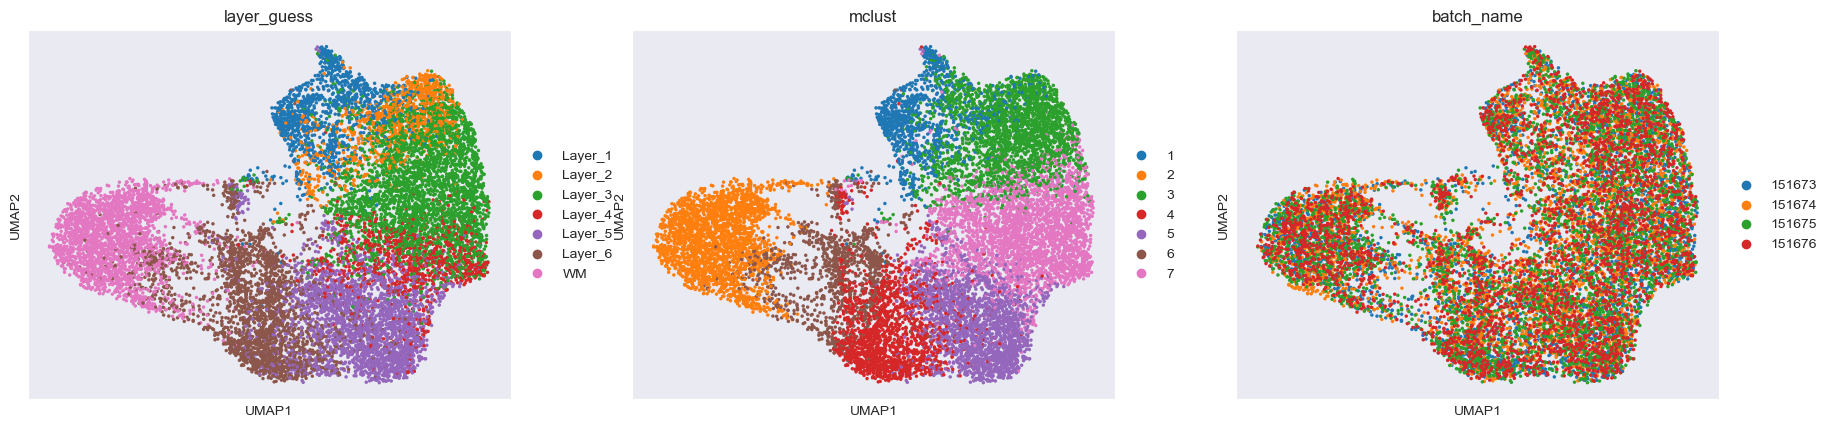

In [5]:
# %%
sc.pp.neighbors(adata, use_rep='SEDR.Harmony', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['layer_guess', 'mclust', 'batch_name'], show=True, size=25, save=False)

In [6]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(adata[adata.obs['batch_name'] == section_id])

spot_size = 300
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['layer_guess'], Batch_list[bb].obs['mclust']), 3))


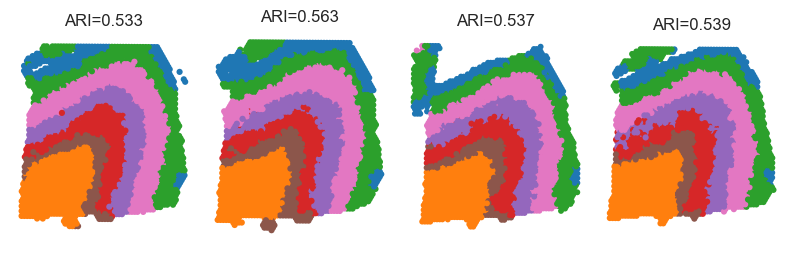

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [8]:
from STG3Net import Metrics
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
ARI = Metrics.compute_ARI(sub_adata, 'layer_guess', 'mclust')
print(f"总体ARI: {ARI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = Metrics.compute_ARI(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"{name} ARI: {ARI}")

总体ARI: 0.5411825723914747
151673 ARI: 0.5325370538188593
151674 ARI: 0.5631444172450242
151675 ARI: 0.5368735163283508
151676 ARI: 0.5386787607733615


In [9]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
NMI = Metrics.compute_NMI(sub_adata, 'layer_guess', 'mclust')
print(f"总体NMI: {NMI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    NMI = Metrics.compute_NMI(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"{name} NMI: {NMI}")

总体NMI: 0.6772210590615004
151673 NMI: 0.6884399452658047
151674 NMI: 0.6950489675859675
151675 NMI: 0.673329346026535
151676 NMI: 0.6810809170988718


In [10]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
HOM = Metrics.compute_HOM(sub_adata, 'layer_guess', 'mclust')
print(f"总体HOM: {HOM}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    HOM = Metrics.compute_HOM(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"{name} HOM: {HOM}")

总体HOM: 0.6846133532529008
151673 HOM: 0.6997475454220384
151674 HOM: 0.7064439745535049
151675 HOM: 0.6767135632283581
151676 HOM: 0.6869543892958054


In [11]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
COM = Metrics.compute_COM(sub_adata, 'layer_guess', 'mclust')
print(f"总体COM: {COM}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    COM = Metrics.compute_COM(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"{name} COM: {COM}")

总体COM: 0.6699867000361325
151673 COM: 0.677491984786151
151674 COM: 0.6840157302830283
151675 COM: 0.669978809058345
151676 COM: 0.6753070300299777


In [12]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
CHAOS = Metrics.compute_CHAOS(sub_adata, 'mclust')
print(f"总体CHAOS: {CHAOS}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    CHAOS = Metrics.compute_CHAOS(sub_adata_tmp, 'mclust')
    print(f"{name} CHAOS: {CHAOS}")

总体CHAOS: 0.019128639816173246
151673 CHAOS: 0.06054978596220208
151674 CHAOS: 0.05985936270157466
151675 CHAOS: 0.06043850193937624
151676 CHAOS: 0.06257260345424737


In [13]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
PAS = Metrics.compute_PAS(sub_adata, 'mclust')
print(f"总体PAS: {PAS}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    PAS = Metrics.compute_PAS(sub_adata_tmp, 'mclust')
    print(f"{name} PAS: {PAS}")

总体PAS: 0.24060942217229517
151673 PAS: 0.024646912212683468
151674 PAS: 0.03191196698762036
151675 PAS: 0.03140773976444195
151676 PAS: 0.04430195278344506


In [14]:
import harmonypy as hm

def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1) / num_batchs
    norm_domain = (LISI_domain_norm - 1) / num_domains
    LISI = 2 * (1 - norm_domain) * norm_batch / (1 - norm_domain + norm_batch)
    return LISI, norm_batch, norm_domain


sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
LISI, norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'SEDR.Harmony', 'batch_name', 'layer_guess')

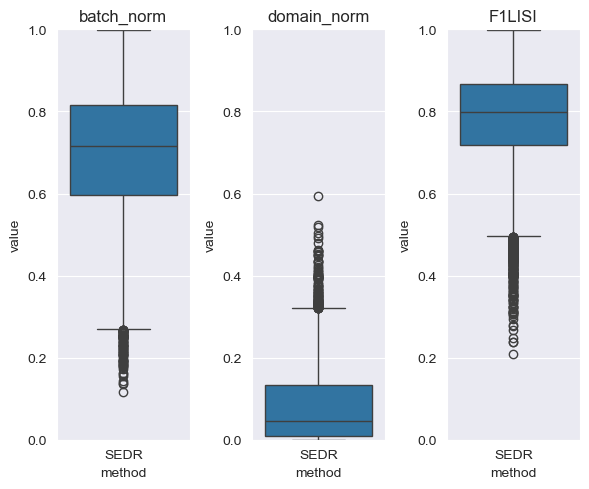

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

df_batch_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'SEDR',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

In [16]:
file_name = 'SEDR_Donor3.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)

Loading and preprocessing data...


100%|██████████| 4/4 [00:06<00:00,  1.54s/it]


Data loaded: 15101 cells, 2000 genes
PCA shape: (15101, 200)
Creating and training SEDR model...


100%|██████████| 500/500 [00:07<00:00, 67.45it/s]
2025-07-15 21:01:27,812 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


Extracting latent embeddings...


2025-07-15 21:01:31,871 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-07-15 21:01:31,968 - harmonypy - INFO - Iteration 1 of 10
2025-07-15 21:01:38,371 - harmonypy - INFO - Iteration 2 of 10
2025-07-15 21:01:42,427 - harmonypy - INFO - Iteration 3 of 10
2025-07-15 21:01:46,468 - harmonypy - INFO - Iteration 4 of 10
2025-07-15 21:01:50,550 - harmonypy - INFO - Iteration 5 of 10
2025-07-15 21:01:55,020 - harmonypy - INFO - Iteration 6 of 10
2025-07-15 21:01:58,682 - harmonypy - INFO - Iteration 7 of 10
2025-07-15 21:02:01,370 - harmonypy - INFO - Iteration 8 of 10
2025-07-15 21:02:03,873 - harmonypy - INFO - Iteration 9 of 10
2025-07-15 21:02:06,084 - harmonypy - INFO - Converged after 9 iterations


Clustering with mclust...
fitting ...
  |======================================================================| 100%


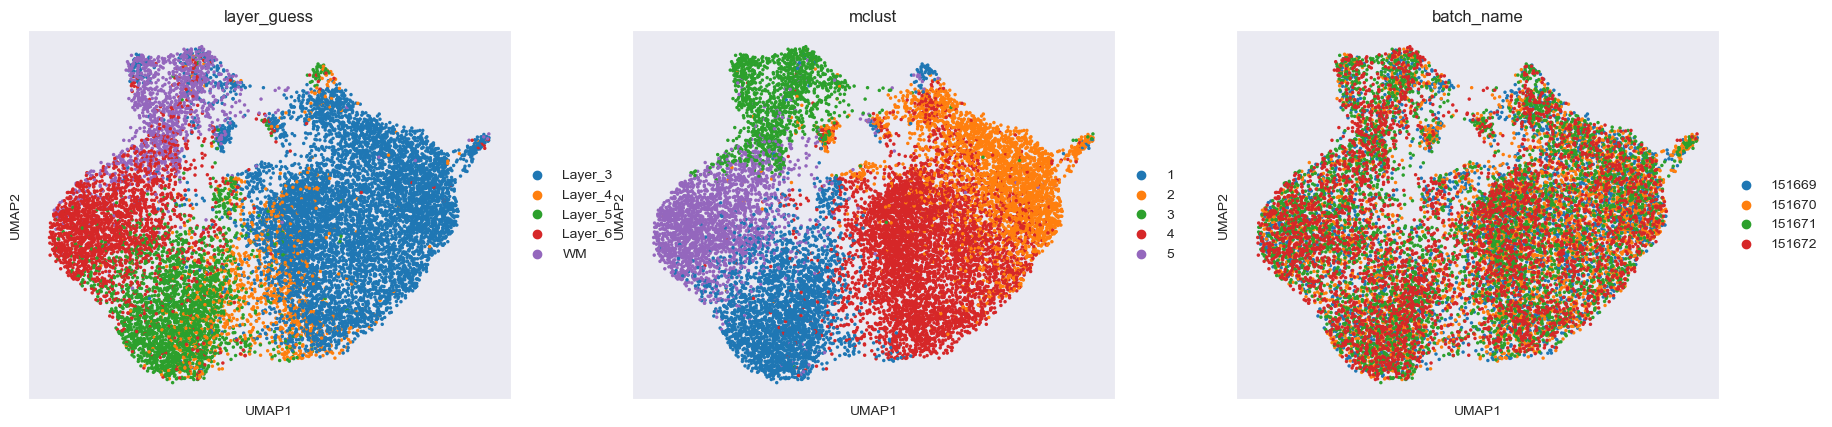

In [9]:
proj_list = ['151669','151670','151671','151672']

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

method = 'mclust'

num_cluster = 5 if proj_list == ['151669','151670','151671','151672'] else 7

# Load and preprocess data
print("Loading and preprocessing data...")
adata, graph_dict = get_data(proj_list, k=12)

print(f"Data loaded: {adata.shape[0]} cells, {adata.shape[1]} genes")
print(f"PCA shape: {adata.obsm['X_pca'].shape}")

# Create SEDR model
print("Creating and training SEDR model...")
sedr_model = Sedr(
    X=adata.obsm['X_pca'],
    graph_dict=graph_dict,
    rec_w=10,      # Reconstruction loss weight
    gcn_w=0.1,     # GCN loss weight
    dec_kl_w=10,   # DEC KL divergence weight
    device=device
)

# Train the model with DEC
sedr_model.train_with_dec(
    epochs=500,
    dec_interval=20,
    dec_tol=0.00
)

# Get latent embeddings
print("Extracting latent embeddings...")
latent_z, q, feat_x, gnn_z = sedr_model.process()
adata.obsm['latent'] = latent_z

import harmonypy as hm

meta_data = adata.obs[['batch_name']]

data_mat = adata.obsm['latent']
vars_use = ['batch_name']
ho = hm.run_harmony(data_mat, meta_data, vars_use)

res = pd.DataFrame(ho.Z_corr).T
res_df = pd.DataFrame(data=res.values, columns=['X{}'.format(i+1) for i in range(res.shape[1])], index=adata.obs.index)
adata.obsm[f'SEDR.Harmony'] = res_df
adata.obsm['SEDR.Harmony'] = adata.obsm['SEDR.Harmony'].values
# Perform clustering using mclust
print("Clustering with mclust...")
adata = mclust_R(adata, n_clusters=num_cluster, use_rep='SEDR.Harmony', key_added='mclust')

sc.pp.neighbors(adata, use_rep='SEDR.Harmony', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['layer_guess', 'mclust', 'batch_name'], show=True, size=25, save=False)

In [10]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
ARI = ari_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total ARI:{ARI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

total ARI:0.49058647050120935
151669 ARI:0.42005754645678967
151670 ARI:0.40602950465461074
151671 ARI:0.5736144845836213
151672 ARI:0.5617937688011105


In [18]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS

sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
# 定义新的计算指标函数
def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'layer_guess', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

整个数据集的指标:
ARI: 0.47839556454517784
NMI: 0.6062157503140216
HOM: 0.6453299999693306
COM: 0.5715720606113658
CHAOS: 0.022767644192056236
PAS: 0.2568041851533011

每个切片的指标:

切片 151669:
ARI: 0.41554973272334145
NMI: 0.5654169921854187
HOM: 0.6144862863128657
COM: 0.5236049518499395
CHAOS: 0.06250246910267572
PAS: 0.0594059405940594

切片 151670:
ARI: 0.3739321774299146
NMI: 0.5264569860383205
HOM: 0.5927523633787373
COM: 0.47349926782381874
CHAOS: 0.06251701910752881
PAS: 0.06371986222732491

切片 151671:
ARI: 0.568986465792371
NMI: 0.6877227999563547
HOM: 0.7240300372407347
COM: 0.6548830119826707
CHAOS: 0.05853513794191125
PAS: 0.026142193989738577

切片 151672:
ARI: 0.5699497225001225
NMI: 0.6715339199898642
HOM: 0.6903425574423359
COM: 0.6537229959879663
CHAOS: 0.06010004217923235
PAS: 0.028034979423868314


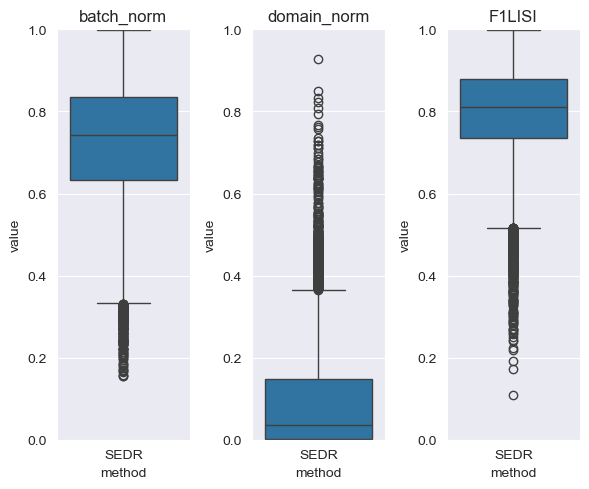

In [19]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'SEDR.Harmony', 'batch_name', 'layer_guess')

df_batch_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'SEDR',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

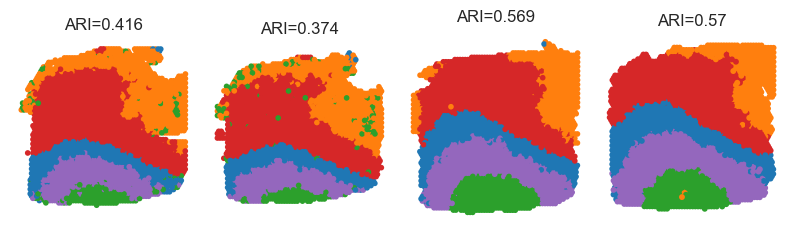

In [20]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(adata[adata.obs['batch_name'] == section_id])

spot_size = 300
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['layer_guess'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [11]:
file_name = 'SEDR_Donor2.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)

Loading and preprocessing data...


100%|██████████| 4/4 [00:07<00:00,  1.84s/it]


Data loaded: 17985 cells, 2000 genes
PCA shape: (17985, 200)
Creating and training SEDR model...


100%|██████████| 200/200 [00:02<00:00, 82.54it/s]
2025-07-15 20:35:53,708 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


Extracting latent embeddings...


2025-07-15 20:35:57,936 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-07-15 20:35:58,040 - harmonypy - INFO - Iteration 1 of 10
2025-07-15 20:36:04,797 - harmonypy - INFO - Iteration 2 of 10
2025-07-15 20:36:09,083 - harmonypy - INFO - Iteration 3 of 10
2025-07-15 20:36:13,921 - harmonypy - INFO - Iteration 4 of 10
2025-07-15 20:36:18,383 - harmonypy - INFO - Iteration 5 of 10
2025-07-15 20:36:23,669 - harmonypy - INFO - Iteration 6 of 10
2025-07-15 20:36:28,106 - harmonypy - INFO - Iteration 7 of 10
2025-07-15 20:36:32,844 - harmonypy - INFO - Iteration 8 of 10
2025-07-15 20:36:36,253 - harmonypy - INFO - Iteration 9 of 10
2025-07-15 20:36:41,236 - harmonypy - INFO - Iteration 10 of 10
2025-07-15 20:36:46,338 - harmonypy - INFO - Converged after 10 iterations


Clustering with mclust...
fitting ...
  |======================================================================| 100%


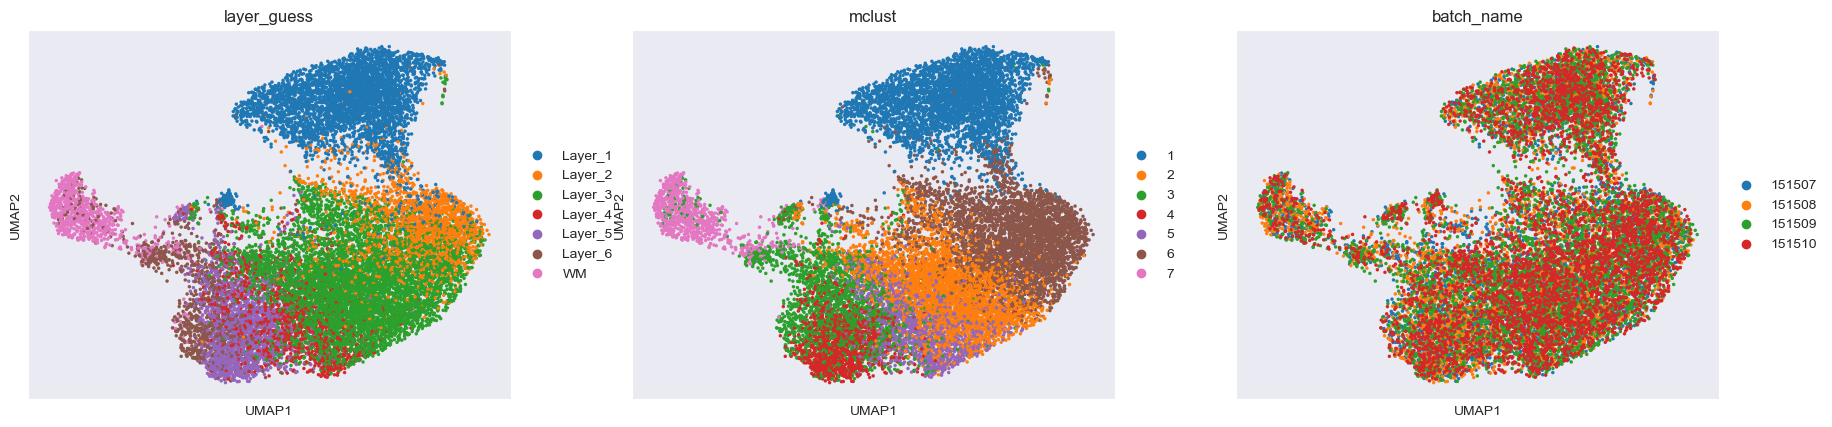

In [4]:
proj_list = ['151507','151508','151509','151510']

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

method = 'mclust'

num_cluster = 5 if proj_list == ['151669','151670','151671','151672'] else 7

# Load and preprocess data
print("Loading and preprocessing data...")
adata, graph_dict = get_data(proj_list, k=12)

print(f"Data loaded: {adata.shape[0]} cells, {adata.shape[1]} genes")
print(f"PCA shape: {adata.obsm['X_pca'].shape}")

# Create SEDR model
print("Creating and training SEDR model...")
sedr_model = Sedr(
    X=adata.obsm['X_pca'],
    graph_dict=graph_dict,
    rec_w=10,      # Reconstruction loss weight
    gcn_w=0.1,     # GCN loss weight
    dec_kl_w=10,   # DEC KL divergence weight
    device=device
)

# Train the model with DEC
sedr_model.train_with_dec(
    epochs=200,
    dec_interval=20,
    dec_tol=0.00
)

# Get latent embeddings
print("Extracting latent embeddings...")
latent_z, q, feat_x, gnn_z = sedr_model.process()
adata.obsm['latent'] = latent_z

import harmonypy as hm

meta_data = adata.obs[['batch_name']]

data_mat = adata.obsm['latent']
vars_use = ['batch_name']
ho = hm.run_harmony(data_mat, meta_data, vars_use)

res = pd.DataFrame(ho.Z_corr).T
res_df = pd.DataFrame(data=res.values, columns=['X{}'.format(i+1) for i in range(res.shape[1])], index=adata.obs.index)
adata.obsm[f'SEDR.Harmony'] = res_df
adata.obsm['SEDR.Harmony'] = adata.obsm['SEDR.Harmony'].values
# Perform clustering using mclust
print("Clustering with mclust...")
adata = mclust_R(adata, n_clusters=num_cluster, use_rep='SEDR.Harmony', key_added='mclust')

sc.pp.neighbors(adata, use_rep='SEDR.Harmony', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['layer_guess', 'mclust', 'batch_name'], show=True, size=25, save=False)

In [5]:
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]
ARI = ari_score(sub_adata.obs['layer_guess'], sub_adata.obs['mclust'])
print(f"total ARI:{ARI}")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_adata_tmp.obs['layer_guess'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

total ARI:0.5098404253719447
151507 ARI:0.5203640399546603
151508 ARI:0.5206024573597383
151509 ARI:0.512383316048628
151510 ARI:0.5365566909734527


In [23]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS
sub_adata = adata[~pd.isnull(adata.obs['layer_guess'])]

# 定义新的计算指标函数
def compute_metrics(adata, true_label_key, pred_label_key):
    # 使用Metrics.py中定义的函数计算各项指标
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'layer_guess', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in proj_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'layer_guess', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

整个数据集的指标:
ARI: 0.3963248281526689
NMI: 0.6142869794285526
HOM: 0.6403672646705727
COM: 0.5902479089179674
CHAOS: 0.028428341290284546
PAS: 0.7492910758965805

每个切片的指标:

切片 151507:
ARI: 0.45604114763633996
NMI: 0.6645513766350243
HOM: 0.672271756422847
COM: 0.6570063055335648
CHAOS: 0.05646640040181613
PAS: 0.02937692489931296

切片 151508:
ARI: 0.4251602090857938
NMI: 0.6513192759788444
HOM: 0.6722905996336149
COM: 0.6316167265090082
CHAOS: 0.055167975572178486
PAS: 0.02716274823099749

切片 151509:
ARI: 0.4057839407794582
NMI: 0.6336977469311065
HOM: 0.6835139849179299
COM: 0.5906496946528438
CHAOS: 0.05399460168001853
PAS: 0.03153717627401838

切片 151510:
ARI: 0.4125779240155619
NMI: 0.6282299088434729
HOM: 0.6767548248453049
COM: 0.5861981218796436
CHAOS: 0.05518941957389679
PAS: 0.031991294885745376


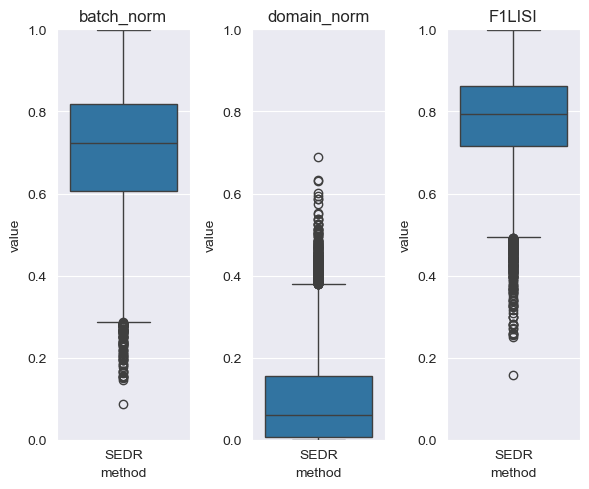

In [24]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'SEDR.Harmony', 'batch_name', 'layer_guess')

df_batch_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'SEDR',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'SEDR',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

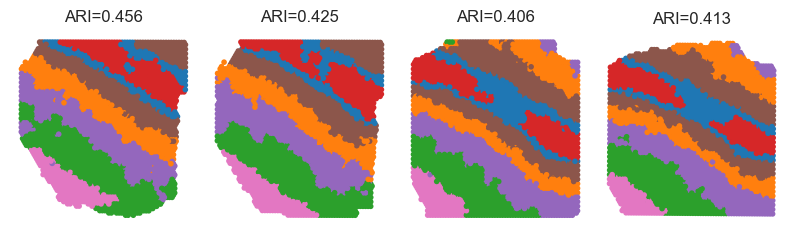

In [25]:
Batch_list = []
for section_id in proj_list:
    Batch_list.append(adata[adata.obs['batch_name'] == section_id])

spot_size = 300
title_size = 12
ARI_list = []
for bb in range(len(proj_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['layer_guess'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(proj_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()

In [6]:
file_name = 'SEDR_Donor1.h5ad'
file_path = f'C:\Code\Answer\DLPFC\\{file_name}'

sub_adata.write(file_path)